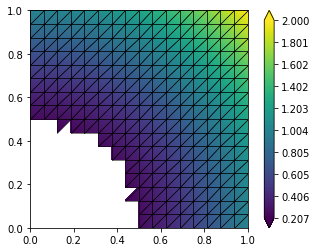

number of dofs: 1089 integral over filtered domain 0.6413014729817705


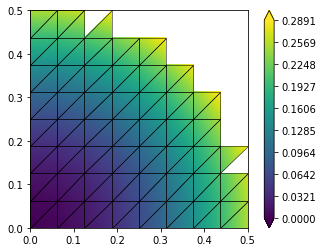

number of dofs: 239 integral over filtered domain 0.025365193684895825


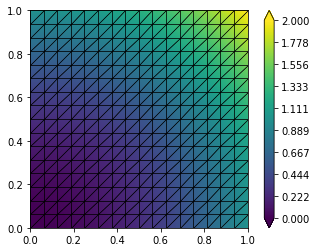

number of dofs: 1089 integral over filtered domain 0.6666666666666667


In [1]:
from ufl import SpatialCoordinate, dot
from dune.grid import cartesianDomain
from dune.alugrid import aluConformGrid as leafGridView
from dune.fem.view import filteredGridView
from dune.fem.space import lagrange

gridView = leafGridView( cartesianDomain([0,0],[1,1],[16,16]) )

filteredView = filteredGridView(gridView, lambda e: e.geometry.center.two_norm > 0.5, domainId=1)
space = lagrange(filteredView, order=2)
x = SpatialCoordinate(space)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot()
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())

filteredView = filteredGridView(gridView, lambda e: e.geometry.center.two_norm < 0.5, domainId=1,
                                useFilteredIndexSet=True)
space = lagrange(filteredView, order=2)
x = SpatialCoordinate(space)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot()
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())

space = lagrange(gridView, order=2)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot()
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())